# Video Games Database Queries

In [4]:
import sqlite3

# connect to DB, create cursor
conn = sqlite3.connect('video_games.db')
cur = conn.cursor()

#List all tables
cur.execute("SELECT name FROM sqlite_master WHERE type='table';")

# Fetch results
tables = cur.fetchall()

# Print table names
for table in tables:
    print(table[0])

GameID
PlatformID
CriticID
CriticReviewsTable
GamePlatformID
UserID
UserReviewsTable
CompositeSentimentScoresTable
GamePlatformSentimentTable
GameplayTable
GameVarsTable
RatingsTable
SentimentScoresTable


In [3]:
from sqlalchemy import create_engine, inspect

# Create an engine that connects to the video_games.db file
engine = create_engine('sqlite:///video_games.db')

# Create an inspector
inspector = inspect(engine)

# Get table names
table_names = inspector.get_table_names()

# Print the table names
for table in table_names:
    print(table)

CompositeSentimentScoresTable
CriticID
CriticReviewsTable
GameID
GamePlatformID
GamePlatformSentimentTable
GameVarsTable
GameplayTable
PlatformID
RatingsTable
SentimentScoresTable
UserID
UserReviewsTable


In [6]:
# Find the top-10 best-selling games globally

cur.execute("""
    SELECT gv.GameID, g.game_title, gv.Total_Sales
    FROM GameVarsTable gv
    JOIN GameID g ON gv.GameID = g.GameID
    ORDER BY Total_Sales DESC
    LIMIT 10
""")

# Fetch the results
results = cur.fetchall()

# Print the results
for row in results:
    display(row)

(2874, 'wii sports', 82.74000000000001)

(993, 'grand theft auto v', 55.92)

(1393, 'mario kart wii', 35.830000000000005)

(2876, 'wii sports resort', 33.0)

(327, 'call of duty: black ops', 31.04)

(332, 'call of duty: modern warfare 3', 30.840000000000003)

(1713, 'new super mario bros.', 30.01)

(328, 'call of duty: black ops ii', 29.73)

(2872, 'wii play', 29.01)

(1716, 'new super mario bros. wii', 28.61)

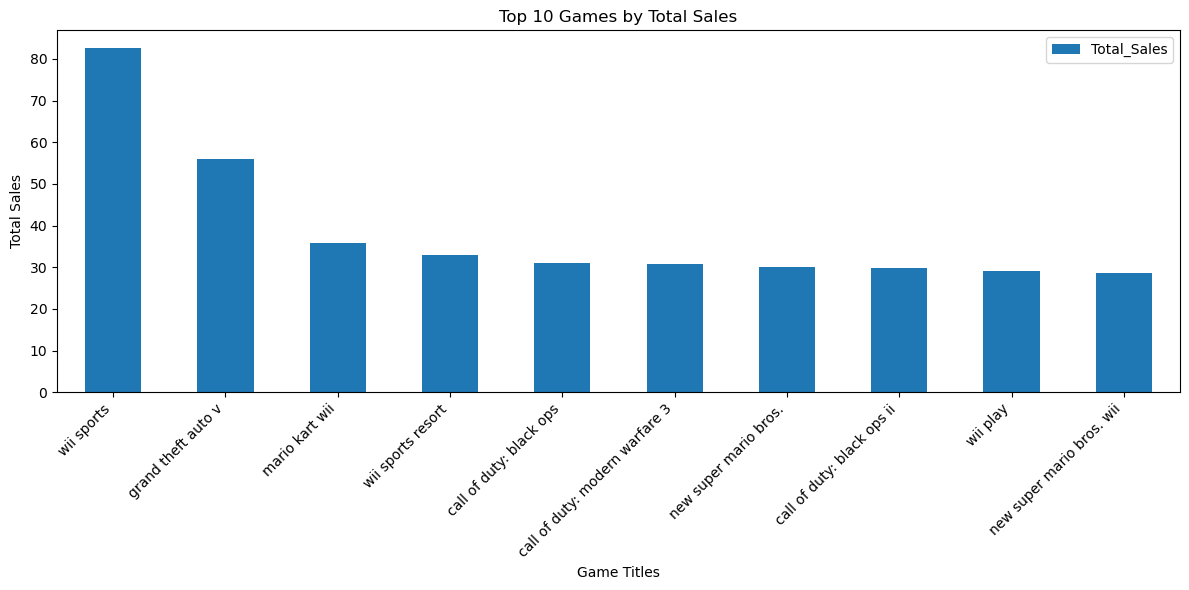

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert results to a pandas DataFrame
df = pd.DataFrame(results, columns=['GameID', 'game_title', 'Total_Sales'])

# Create the bar chart
df.plot(kind='bar', x='game_title', y='Total_Sales', figsize=(12, 6))

plt.title('Top 10 Games by Total Sales')
plt.xlabel('Game Titles')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [12]:
# Compare sales across different platforms

cur.execute("""
    SELECT gv.GameID, gp.platform, ROUND(SUM(gv.total_sales)) as Total_Platform_Sales
    FROM GameVarsTable gv
    JOIN GamePlatformID gp ON gp.GameID = gv.GameID
    GROUP BY gp.platform
    ORDER BY Total_Platform_Sales DESC;
""")

# Fetch the results
results2 = cur.fetchall()

# Print the results
for row in results2:
    display(row)


(8, 'xbox-360', 188.0)

(44, 'pc', 148.0)

(8, 'playstation-3', 144.0)

(9, 'playstation-2', 137.0)

(225, 'xbox', 64.0)

(162, 'wii', 61.0)

... (8 outputs left out)

(270, 'playstation-vita', 10.0)

(203, 'nintendo-switch', 4.0)

(67, 'xbox-series-x', 1.0)

(67, 'playstation-5', 1.0)

<Axes: xlabel='Platform'>

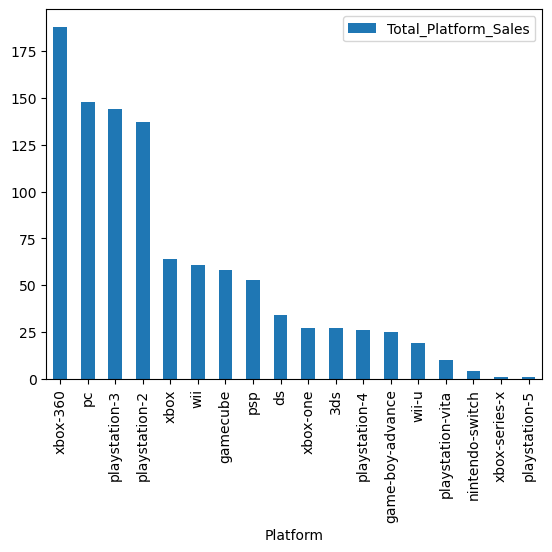

In [13]:
#Viz
df = pd.DataFrame(results2, columns=['GameID', 'Platform', 'Total_Platform_Sales'])
df.plot(kind='bar', x='Platform', y='Total_Platform_Sales')

In [15]:
# Analyze sales by genre and region

cur.execute("""
    SELECT gv.Genre, ROUND(SUM(gv.NA_Sales)
    ) as "North America",
        ROUND(SUM(gv.EU_Sales)) as Europe, ROUND(SUM(gv.JP_Sales)) as Japan
    FROM GameVarsTable gv
    GROUP BY gv.Genre;
""")

# Fetch the results
results3 = cur.fetchall()

# Print the results
for row in results3:
    display(row)


('Action', 568.0, 381.0, 69.0)

('Adventure', 35.0, 25.0, 9.0)

('Fighting', 120.0, 54.0, 20.0)

('Misc', 203.0, 107.0, 29.0)

('Platform', 187.0, 107.0, 39.0)

('Puzzle', 33.0, 24.0, 15.0)

... (2 outputs left out)

('Shooter', 416.0, 247.0, 18.0)

('Simulation', 76.0, 57.0, 25.0)

('Sports', 407.0, 234.0, 34.0)

('Strategy', 32.0, 24.0, 4.0)

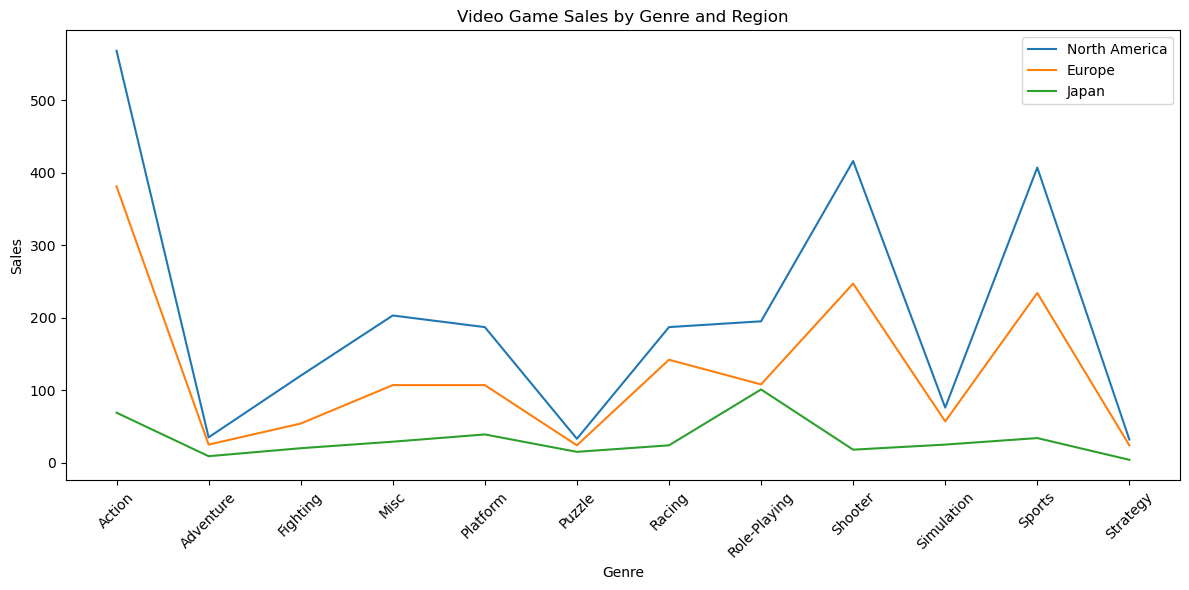

In [16]:
#VIZ
genres = [row[0] for row in results3]
na_sales = [row[1] for row in results3]
eu_sales = [row[2] for row in results3]
jp_sales = [row[3] for row in results3]

plt.figure(figsize=(12, 6))
plt.plot(genres, na_sales, label='North America')
plt.plot(genres, eu_sales, label='Europe')
plt.plot(genres, jp_sales, label='Japan')

plt.xlabel('Genre')
plt.ylabel('Sales')
plt.title('Video Game Sales by Genre and Region')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [19]:
## Analyze sales by genre and region PERCENTAGES
import numpy as np

cur.execute("""
    SELECT 
        gv.Genre,
        ROUND(SUM(gv.NA_Sales), 2) as "North America Sales",
        ROUND(SUM(gv.NA_Sales) * 100.0 / SUM(SUM(gv.NA_Sales)) OVER(), 2) as "North America %",
        ROUND(SUM(gv.EU_Sales), 2) as "Europe Sales",
        ROUND(SUM(gv.EU_Sales) * 100.0 / SUM(SUM(gv.EU_Sales)) OVER(), 2) as "Europe %",
        ROUND(SUM(gv.JP_Sales), 2) as "Japan Sales",
        ROUND(SUM(gv.JP_Sales) * 100.0 / SUM(SUM(gv.JP_Sales)) OVER(), 2) as "Japan %"
    FROM GameVarsTable gv
    GROUP BY gv.Genre
    ORDER BY gv.Genre;
""")

# Fetch the results
results4 = cur.fetchall()

# Print the results
for row in results4:
    display(row)


('Action', 567.57, 23.09, 380.9, 25.23, 68.84, 17.85)

('Adventure', 34.99, 1.42, 24.65, 1.63, 8.51, 2.21)

('Fighting', 119.6, 4.87, 53.73, 3.56, 19.91, 5.16)

('Misc', 203.44, 8.28, 107.09, 7.09, 28.88, 7.49)

('Platform', 186.93, 7.6, 107.38, 7.11, 38.76, 10.05)

('Puzzle', 32.64, 1.33, 24.05, 1.59, 14.91, 3.87)

... (2 outputs left out)

('Shooter', 416.45, 16.94, 246.73, 16.35, 17.77, 4.61)

('Simulation', 75.53, 3.07, 57.15, 3.79, 25.4, 6.59)

('Sports', 407.26, 16.57, 234.4, 15.53, 34.45, 8.93)

('Strategy', 31.92, 1.3, 23.51, 1.56, 3.82, 0.99)

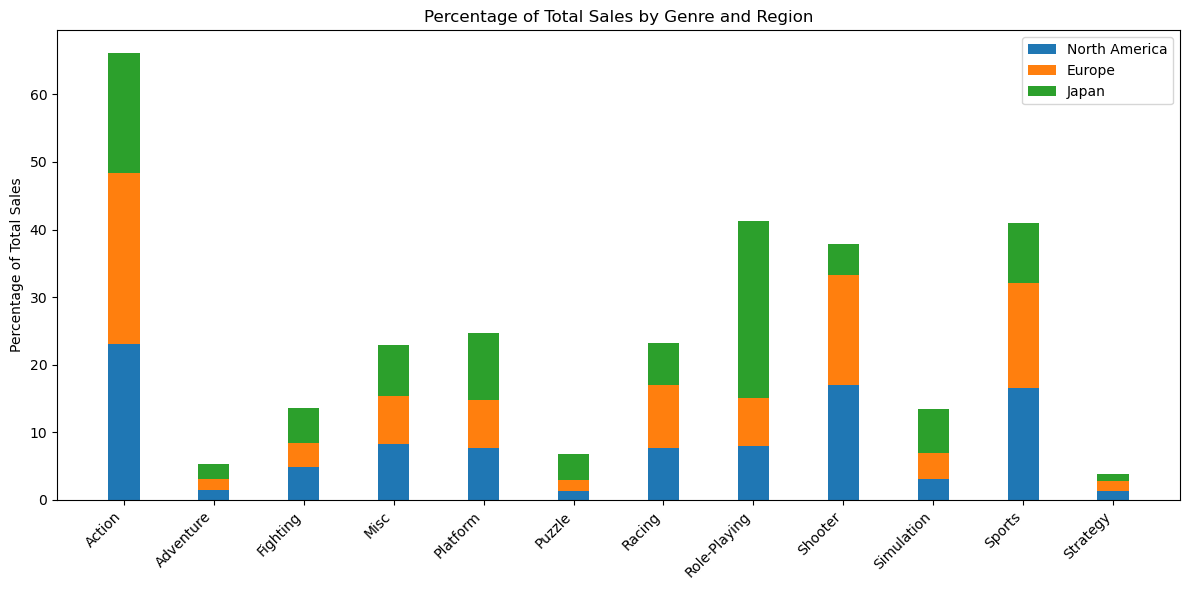

In [21]:
#VIZ
import numpy as np

genres = [row[0] for row in results4]
na_pct = [row[2] for row in results4]
eu_pct = [row[4] for row in results4]
jp_pct = [row[6] for row in results4]

fig, ax = plt.subplots(figsize=(12, 6))
width = 0.35

ax.bar(genres, na_pct, width, label='North America')
ax.bar(genres, eu_pct, width, bottom=na_pct, label='Europe')
ax.bar(genres, jp_pct, width, bottom=np.array(na_pct) + np.array(eu_pct), label='Japan')

ax.set_ylabel('Percentage of Total Sales')
ax.set_title('Percentage of Total Sales by Genre and Region')
ax.legend()

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [22]:
## Analyze sales by genre and region PERCENTAGES
import numpy as np

cur.execute("""
    SELECT 
        gv.Genre,
        ROUND(SUM(gv.NA_Sales), 2) as "North America Sales",
        ROUND(SUM(gv.NA_Sales) * 100.0 / SUM(SUM(gv.NA_Sales)) OVER(), 2) as "North America %",
        ROUND(SUM(gv.EU_Sales), 2) as "Europe Sales",
        ROUND(SUM(gv.EU_Sales) * 100.0 / SUM(SUM(gv.EU_Sales)) OVER(), 2) as "Europe %",
        ROUND(SUM(gv.JP_Sales), 2) as "Japan Sales",
        ROUND(SUM(gv.JP_Sales) * 100.0 / SUM(SUM(gv.JP_Sales)) OVER(), 2) as "Japan %"
    FROM GameVarsTable gv
    GROUP BY gv.Genre
    ORDER BY "North America %" DESC;
""")

# Fetch the results
results5 = cur.fetchall()

# Print the results
for row in results5:
    display(row)

('Action', 567.57, 23.09, 380.9, 25.23, 68.84, 17.85)

('Shooter', 416.45, 16.94, 246.73, 16.35, 17.77, 4.61)

('Sports', 407.26, 16.57, 234.4, 15.53, 34.45, 8.93)

('Misc', 203.44, 8.28, 107.09, 7.09, 28.88, 7.49)

('Role-Playing', 194.71, 7.92, 107.72, 7.14, 100.82, 26.14)

('Racing', 187.04, 7.61, 142.14, 9.42, 23.61, 6.12)

... (2 outputs left out)

('Simulation', 75.53, 3.07, 57.15, 3.79, 25.4, 6.59)

('Adventure', 34.99, 1.42, 24.65, 1.63, 8.51, 2.21)

('Puzzle', 32.64, 1.33, 24.05, 1.59, 14.91, 3.87)

('Strategy', 31.92, 1.3, 23.51, 1.56, 3.82, 0.99)

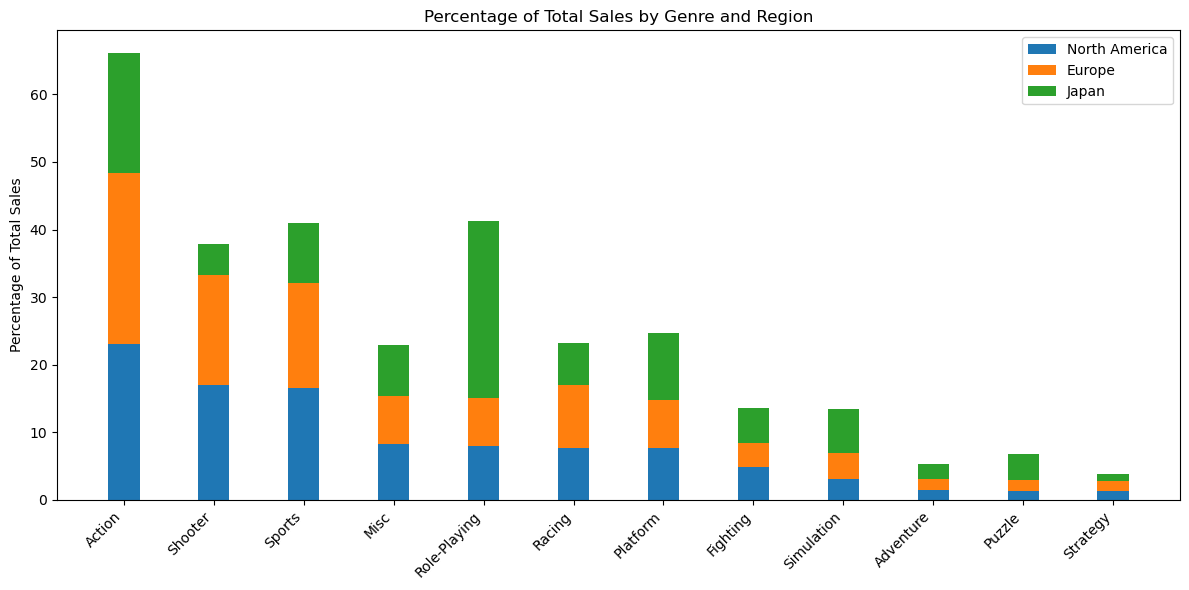

In [23]:
# VIZ

genres = [row[0] for row in results5]
na_pct = [row[2] for row in results5]
eu_pct = [row[4] for row in results5]
jp_pct = [row[6] for row in results5]

fig, ax = plt.subplots(figsize=(12, 6))
width = 0.35

ax.bar(genres, na_pct, width, label='North America')
ax.bar(genres, eu_pct, width, bottom=na_pct, label='Europe')
ax.bar(genres, jp_pct, width, bottom=np.array(na_pct) + np.array(eu_pct), label='Japan')

ax.set_ylabel('Percentage of Total Sales')
ax.set_title('Percentage of Total Sales by Genre and Region')
ax.legend()

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


('Role-Playing', 194.71, 7.92, 107.72, 7.14, 100.82, 26.14)

('Action', 567.57, 23.09, 380.9, 25.23, 68.84, 17.85)

('Platform', 186.93, 7.6, 107.38, 7.11, 38.76, 10.05)

('Sports', 407.26, 16.57, 234.4, 15.53, 34.45, 8.93)

('Misc', 203.44, 8.28, 107.09, 7.09, 28.88, 7.49)

('Simulation', 75.53, 3.07, 57.15, 3.79, 25.4, 6.59)

... (2 outputs left out)

('Shooter', 416.45, 16.94, 246.73, 16.35, 17.77, 4.61)

('Puzzle', 32.64, 1.33, 24.05, 1.59, 14.91, 3.87)

('Adventure', 34.99, 1.42, 24.65, 1.63, 8.51, 2.21)

('Strategy', 31.92, 1.3, 23.51, 1.56, 3.82, 0.99)

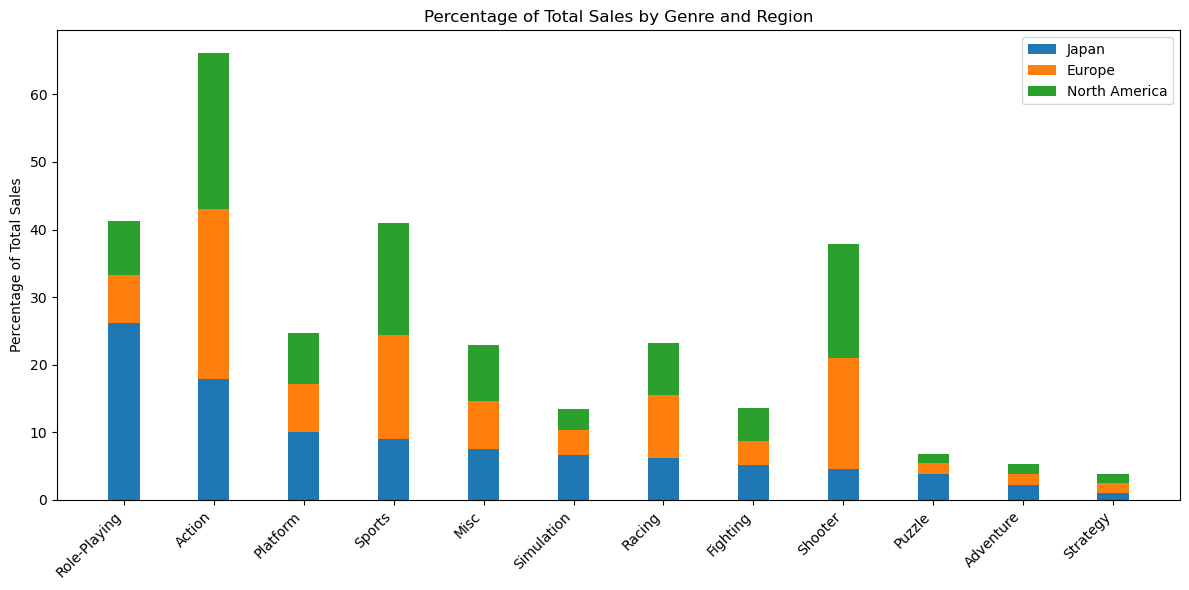

In [26]:
cur.execute("""
    SELECT 
        gv.Genre,
        ROUND(SUM(gv.NA_Sales), 2) as "North America Sales",
        ROUND(SUM(gv.NA_Sales) * 100.0 / SUM(SUM(gv.NA_Sales)) OVER(), 2) as "North America %",
        ROUND(SUM(gv.EU_Sales), 2) as "Europe Sales",
        ROUND(SUM(gv.EU_Sales) * 100.0 / SUM(SUM(gv.EU_Sales)) OVER(), 2) as "Europe %",
        ROUND(SUM(gv.JP_Sales), 2) as "Japan Sales",
        ROUND(SUM(gv.JP_Sales) * 100.0 / SUM(SUM(gv.JP_Sales)) OVER(), 2) as "Japan %"
    FROM GameVarsTable gv
    GROUP BY gv.Genre
    ORDER BY "Japan %" DESC;
""")

# Fetch the results
results6 = cur.fetchall()

# Print the results
for row in results6:
    display(row)

genres = [row[0] for row in results6]
na_pct = [row[2] for row in results6]
eu_pct = [row[4] for row in results6]
jp_pct = [row[6] for row in results6]

fig, ax = plt.subplots(figsize=(12, 6))
width = 0.35

ax.bar(genres, jp_pct, width, label='Japan')
ax.bar(genres, eu_pct, width, bottom=jp_pct, label='Europe')
ax.bar(genres, na_pct, width, bottom=np.array(jp_pct) + np.array(eu_pct), label='North America')

ax.set_ylabel('Percentage of Total Sales')
ax.set_title('Percentage of Total Sales by Genre and Region')
ax.legend()

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

